### I intend to use this notebook only for visualization purposes, showing results and put the main code of the pipeline (i.e. function calls to the main procedures like instantiating the dataset, call to the training loop and so on...)

In [7]:
from dataset import MVTec3D_RGB_Dataset, MVTec2DDataset
from utils.helpers import set_seed, get_device
from visualization import visualize_batch
from utils.data_split import split_data
from torchvision.transforms import v2
from torchinfo import summary
from model import Autoencoder
from engine import train
import torch.nn as nn
import torch


In [8]:
config = {

    'device': 'cuda',
    'num_workers': 0,
    'seed': 42,

    # dataset
    'img_size': (256, 256),
    'batch_size': 64,
}

In [9]:
set_seed(42)
DEVICE = get_device()

Random seed set to 42.
Using device: cuda.


### Dataset and DataLoaders

In [13]:
do_split = True
if do_split:
    # Split a single class
    #split_data(root="./data/MVTec", class_name="bottle", val_ratio=0.15)

    # Or split all classes under data/MVTec at once:
    split_data(root="./data/MVTec", val_ratio=0.15)

[bottle] Already split (Train: 178, Val: 31). Use force=True to re-split.
[pill] Split complete -> Train: 227, Val: 40


In [14]:
transforms = v2.Compose([
    v2.Resize(config['img_size']),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),  # valori in [0, 1]
])

train_dataset = MVTec2DDataset(
    transforms=transforms,
)

train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=config['batch_size'],
    shuffle=True,
    num_workers=config['num_workers'],
    pin_memory=True,
)

val_dataset = MVTec2DDataset(
    transforms=transforms,
    split='validation',
)

val_loader = torch.utils.data.DataLoader(
    val_dataset,
    batch_size=config['batch_size'],
    shuffle=False,
    num_workers=config['num_workers'],
    pin_memory=True,
)

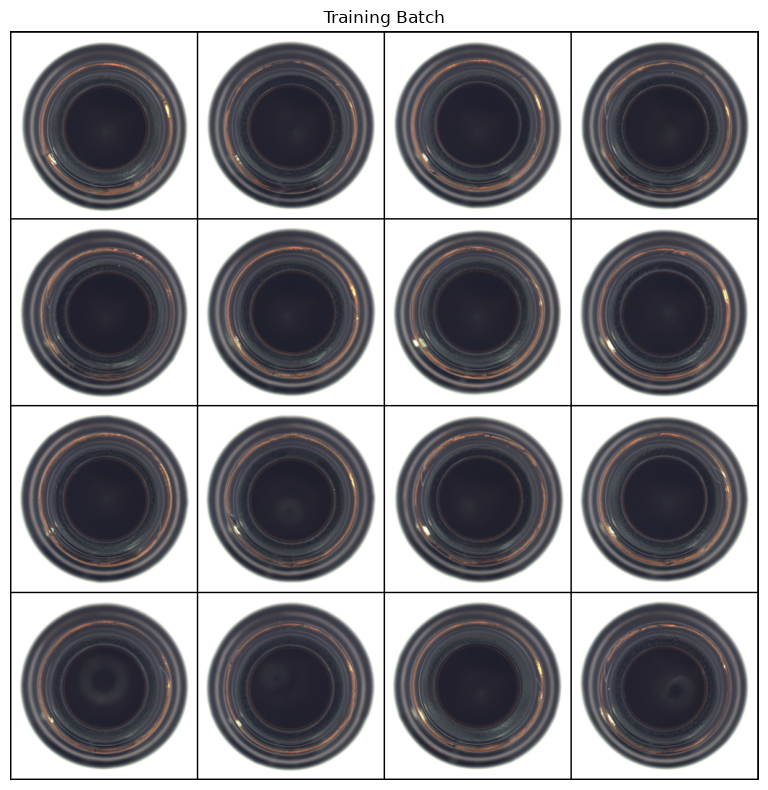

In [15]:
# visualize a batch of images
visualize_batch(train_loader)

### Model Instantiation and training

Input images shape: torch.Size([64, 3, 256, 256])
Reconstructed images shape: torch.Size([64, 3, 256, 256])


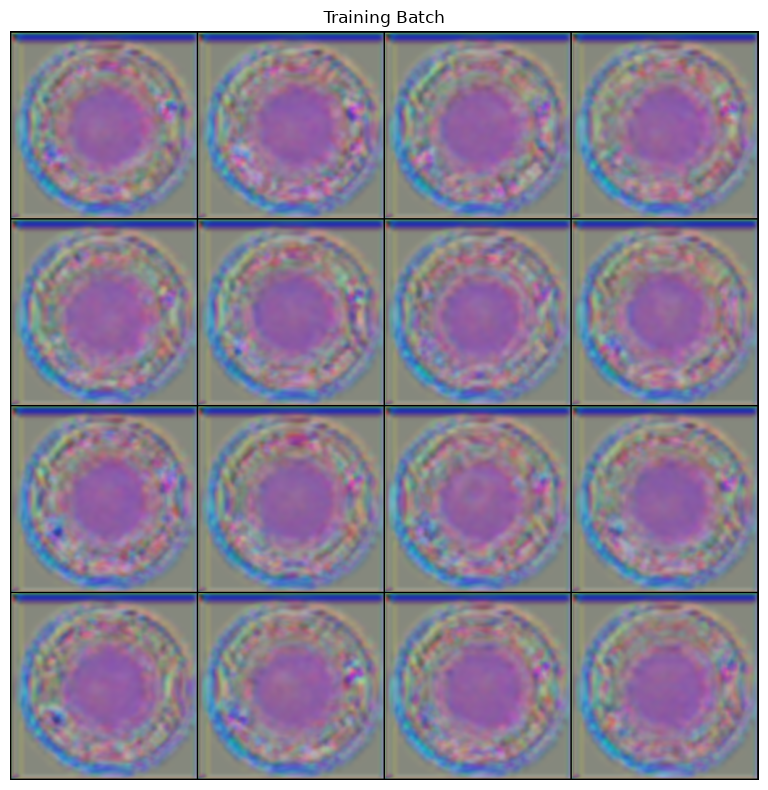

In [16]:
model = Autoencoder(in_channels=3).to(DEVICE)
# single forward pass to check if the model works
sample_batch = next(iter(train_loader))
with torch.no_grad():
    sample_images = sample_batch['image'].to(DEVICE)
    reconstructed_images = model(sample_images)

print(f"Input images shape: {sample_images.shape}")
print(f"Reconstructed images shape: {reconstructed_images.shape}")
visualize_batch(reconstructed_images)

In [17]:
print(summary(model, input_size=(config['batch_size'], 3, *config['img_size']), device=DEVICE))

Layer (type:depth-idx)                   Output Shape              Param #
Autoencoder                              [64, 3, 256, 256]         --
├─Sequential: 1-1                        [64, 256, 32, 32]         --
│    └─EncoderBlock: 2-1                 [64, 64, 128, 128]        --
│    │    └─Sequential: 3-1              [64, 64, 128, 128]        1,920
│    └─EncoderBlock: 2-2                 [64, 128, 64, 64]         --
│    │    └─Sequential: 3-2              [64, 128, 64, 64]         74,112
│    └─EncoderBlock: 2-3                 [64, 256, 32, 32]         --
│    │    └─Sequential: 3-3              [64, 256, 32, 32]         295,680
├─Sequential: 1-2                        [64, 3, 256, 256]         --
│    └─DecoderBlock: 2-4                 [64, 128, 64, 64]         --
│    │    └─Sequential: 3-4              [64, 128, 64, 64]         295,296
│    └─DecoderBlock: 2-5                 [64, 64, 128, 128]        --
│    │    └─Sequential: 3-5              [64, 64, 128, 128]        7

In [18]:
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

history = train(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    epochs=3,
    device=DEVICE,
    save_dir="./experiments/baseline",
)

Epoch [001/003] | Train Loss: 0.07588 | Val Loss: 0.10229


Epoch [002/003] | Train Loss: 0.01028 | Val Loss: 0.03977


Epoch [003/003] | Train Loss: 0.00622 | Val Loss: 0.01607


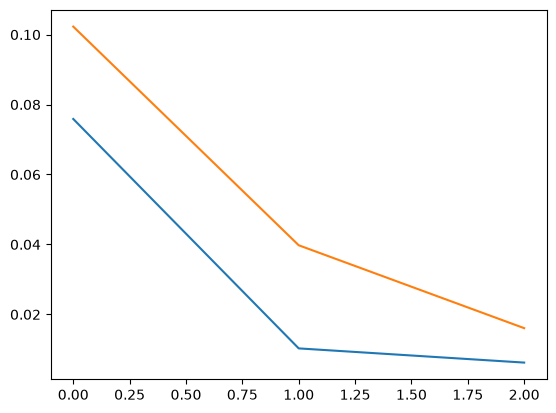

In [19]:
import matplotlib.pyplot as plt

plt.plot(history['train_loss'], label='Train Loss')
plt.plot(history['val_loss'], label='Validation Loss')

In [22]:
target_transforms = v2.Compose([
    v2.Resize(config['img_size'], interpolation=v2.InterpolationMode.NEAREST),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
])

# test dataset
test_dataset = MVTec2DDataset(
    transforms=transforms,
    target_transforms=target_transforms,
    split='test',
)

test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=config['batch_size'],
    shuffle=False,
    num_workers=config['num_workers'],
    pin_memory=True,
)

# single batch forward pass on test set
# batch = next(iter(test_loader))
# with torch.no_grad():
#     test_images = batch['image'].to(DEVICE)
#     reconstructed_test_images = model(test_images)

# # visualize a batch of test images and their reconstructions
# visualize_batch(test_images)

# # visualize a batch of reconstructed test images
# visualize_batch(reconstructed_test_images)



Evaluation -> Image AUROC: 0.7226 | Pixel AUROC: 0.4752


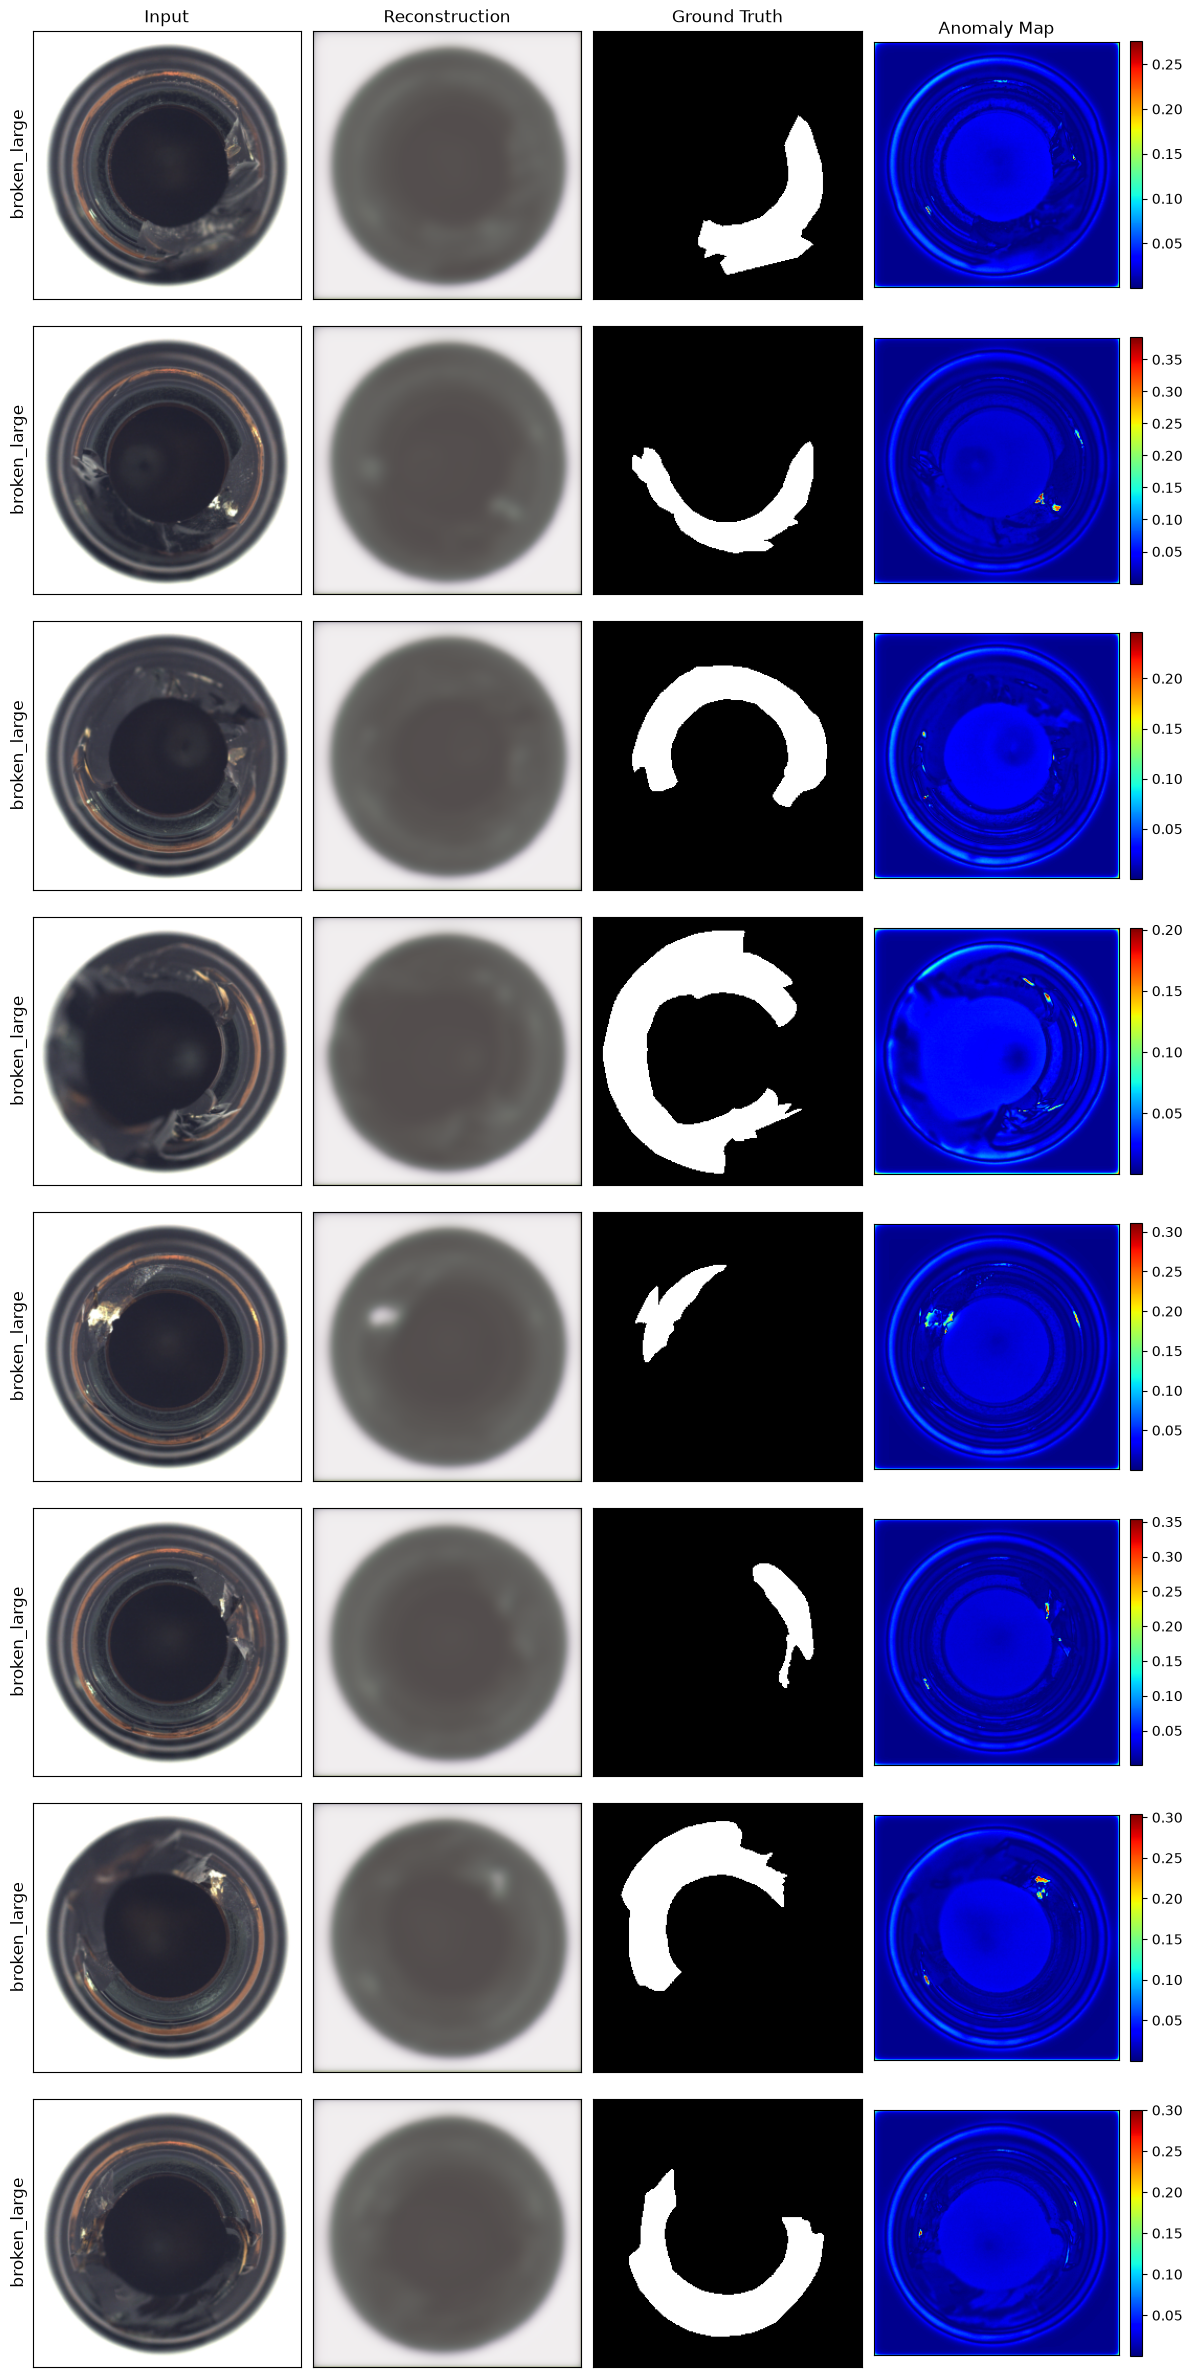

In [23]:
from engine import evaluate
from visualization import visualize_anomalies


# 2. Run quantitative evaluation (Image & Pixel AUROC)
metrics = evaluate(model, test_loader, DEVICE)

# 3. Visualize qualitative anomaly heatmaps
visualize_anomalies(model, test_loader, DEVICE, num_samples=8)